# State and parameter estimation with a parametric echo state network

The Lorenz-63 system has an unknown Rayleigh number, $\rho$. A parametric ESN, trained at $\rho = 24, 26, \dots, 38$ with $\rho$ as an input, forecasts it. The filter estimates $\boldsymbol{\psi} = [\boldsymbol{u}; \boldsymbol{r}; \rho]$ from noisy data of the state (augmented formulation, tutorial 13). Configuration: `scripts/esnda/configs/lorenz63_parametric.yml`.

In [1]:
import numpy as np

from romda.models.physical import Lorenz63
from romda.models.data_driven.rnns import parametric_esn
from romda.observations import Observations
from romda.data_assimilation import deploy
from romda.metrics import state_metrics
from romda.utils import noisy_copy, trajectory
from aux_4X import BLUE, VERMILLION, config, plot_parameter, plot_parameter_scan, plot_sweep

CONFIG = config('lorenz63_parametric')
DA, TRAIN = CONFIG['da'], CONFIG['forecast']['train']

# the first call trains the network (about two minutes); `mu` is the parameter of the network
esn, segments, regimes = parametric_esn(Lorenz63, TRAIN, CONFIG['forecast']['esn'], CONFIG['truth']['noise_level'],
                                        model_kwargs=CONFIG['truth']['params'])
esn.alpha_lims = dict(mu=(20., 45.))       # analyses outside this range are rejected
t_lyap, dt, rho_train = Lorenz63.t_lyap, esn.dt, regimes[0]

T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']
n_steps = int(round((T_STOP + T_FORECAST + 1) * t_lyap / dt))
t = np.arange(n_steps) * dt
RHO_TRUE = DA['rho_true']
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'], inflation=DA['inflation'],
              regimes=regimes, t_extra=T_FORECAST * t_lyap)


def true_system(rho=RHO_TRUE, seed=0, Nt_obs=6):
    """A noisy trajectory at `rho` observed every `Nt_obs` steps (6 steps = 0.11 Lyapunov times)."""
    clean = trajectory(Lorenz63, seed=seed, n_steps=n_steps, dt=dt, constructor_defaults=CONFIG['truth']['params'], rho=rho)
    truth = Observations(y_raw=noisy_copy(clean, CONFIG['truth']['noise_level'], seed), y_true=clean, t_true=t,
                         t_start=T_START * t_lyap, t_stop=T_STOP * t_lyap, Nt_obs=Nt_obs)
    truth.true_parameters = dict(mu=rho)
    return clean, truth


def estimate(clean, truth):
    """State and parameter estimation, from members with rho spread over the training range."""
    esn.alpha0['mu'] = float(np.mean(rho_train))
    run = deploy(esn, truth, measured=[0, 1, 2], est_alpha=['mu'], **FILTER)
    return run, state_metrics(run, truth, t, clean, t_lyap=t_lyap)

## 1. Fixed wrong parameter against estimated parameter

True $\rho = 33.5$, not in the training set:

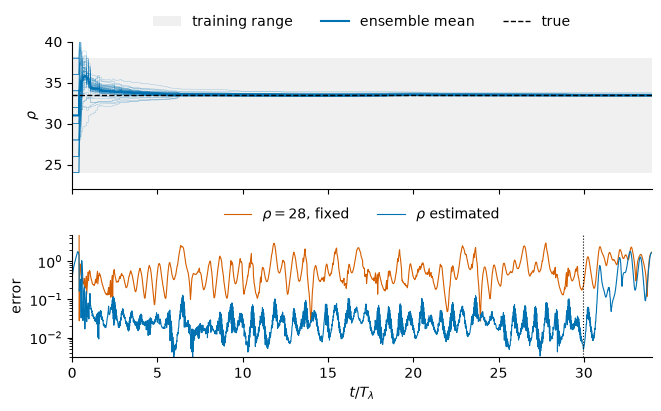

rho fixed at 28: error 0.817, valid time 0.1
rho estimated:   error 0.032, valid time 0.9, rho = 33.47 ± 0.08


In [2]:
clean, truth = true_system()
esn.alpha0['mu'] = 28.
run_fixed = deploy(esn, truth, measured=[0, 1, 2], **FILTER)
run, s = estimate(clean, truth)
plot_parameter(run, {r'$\rho = 28$, fixed': (run_fixed, VERMILLION), r'$\rho$ estimated': (run, BLUE)},
               truth, t, clean, t_lyap, RHO_TRUE, rho_train)
s_fixed = state_metrics(run_fixed, truth, t, clean, t_lyap=t_lyap)
print(f"rho fixed at 28: error {s_fixed['rmse_mean_sync']:.3f}, valid time {s_fixed['valid_time_mean_forecast']:.1f}")
print(f"rho estimated:   error {s['rmse_mean_sync']:.3f}, valid time {s['valid_time_mean_forecast']:.1f}, "
      f"rho = {s['alpha_mu']:.2f} ± {s['alpha_std_mu']:.2f}")

The ensemble converges to the true $\rho$ within five Lyapunov times of data, and the error of the state drops by a factor of 25 with respect to the fixed wrong $\rho$.

## 2. Time between observations

The parameter is identified through the forecast between observations. Four trajectories per interval:

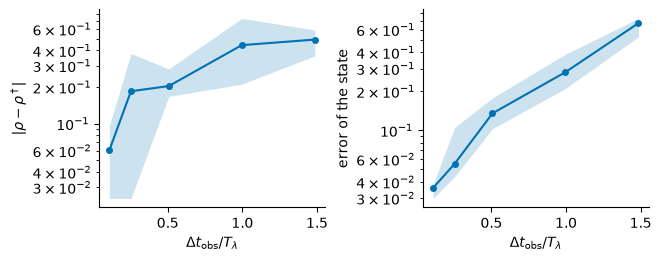

median error of rho:       [0.06 0.18 0.2  0.44 0.49]
median error of the state: [0.036 0.055 0.135 0.281 0.672]


In [3]:
intervals = [6, 14, 28, 55, 82]
sweep = np.array([[[abs(m['alpha_mu'] - RHO_TRUE), m['rmse_mean_last']]
                   for m in (estimate(*true_system(seed=seed, Nt_obs=n))[1] for seed in range(4))] for n in intervals])
plot_sweep(np.array(intervals) * dt / t_lyap, {'': (sweep, BLUE)}, r'$\Delta t_\mathrm{obs}/T_\lambda$',
           [r'$|\rho - \rho^\dagger|$', 'error of the state'], logy=(True, True))
print('median error of rho:      ', np.round(np.median(sweep[..., 0], axis=1), 2))
print('median error of the state:', np.round(np.median(sweep[..., 1], axis=1), 3))

$\rho$ is identified to within 1.5 % up to $1.5\,T_\lambda$ between observations, but the state is tracked only when the observations are a fraction of a Lyapunov time apart.

## 3. Inside and outside the training range

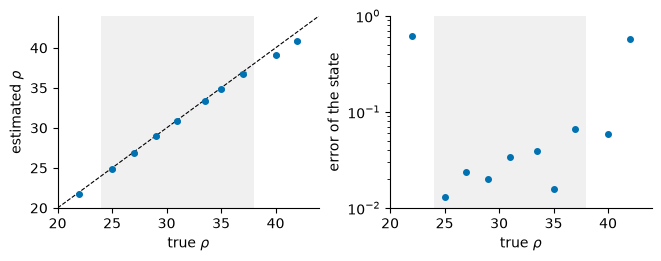

estimated rho: [21.78 24.9  26.87 28.98 30.9  33.38 34.88 36.76 39.15 40.85]


In [4]:
rho_cases = [22., 25., 27., 29., 31., 33.5, 35., 37., 40., 42.]
scan = np.array([[m['alpha_mu'], m['alpha_std_mu'], m['rmse_mean_last']]
                 for m in (estimate(*true_system(rho=r, seed=1))[1] for r in rho_cases)])
plot_parameter_scan(rho_cases, scan, rho_train)
print('estimated rho:', np.round(scan[:, 0], 2))

Inside the training range, the filter recovers $\rho$ to within 0.25. Outside it, the estimate is biased towards the training range and the error of the state grows: the network must be trained on a range that contains the true value. The Lorenz-96 version of this study is `scripts/esnda/run/run_parametric.py`.